# Cross-Lingual Embedding Test — Part 3: pure-Khmer medical queries (hard test)

Parts 1–2 used 10 hand-written queries that kept English medical terms, against 13 chunks. Every model scored ~100%.

Here we use **[khopilot/khmer-medical-qa](https://huggingface.co/datasets/khopilot/khmer-medical-qa)** (18,756 medical QA pairs, English + Khmer translation; stored in `data/khmer-medical-qa/`):

- **Queries**: 200 questions whose Khmer text has **no Latin-script words at all** (no "sepsis", "STEMI", ...)
- **Corpus**: 2,000 answers = the 200 correct ones + 1,800 random distractor answers from the same dataset
- **Three settings**
  - `KM→KM`: Khmer question → Khmer answers
  - `KM→EN`: Khmer question → English answers (**our real setup**: Khmer user, English guideline)
  - `EN→EN`: English question → English answers (baseline: how good is the model without any language gap?)
- **Metrics**: Hit@1, Hit@5, MRR@10

Caveat: the Khmer side is machine-translated from English, so it may be cleaner/more literal than what real Cambodian clinicians type.

In [1]:
# Step 1: Load the 4 models
import os
os.environ["USE_TF"] = "0"   # transformers would import TensorFlow (Keras 3) and fail; we only use PyTorch

import re, json, time
import numpy as np
import pandas as pd
import torch
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

MODELS = {
    "e5-small": dict(id="intfloat/multilingual-e5-small",           qp="query: ", dp="passage: "),
    "BGE-M3":   dict(id="BAAI/bge-m3",                              qp="",        dp=""),
    "SEA-LION": dict(id="aisingapore/SEA-LION-ModernBERT-Embedding-300M", qp="",  dp=""),
    "LaBSE":    dict(id="sentence-transformers/LaBSE",              qp="",        dp=""),
}
for name, cfg in MODELS.items():
    cfg["model"] = SentenceTransformer(cfg["id"], device=device)
    print(f"{name:<10} loaded  (max_seq_length={cfg['model'].max_seq_length})")

/mnt/mahdipou/miniconda3/envs/senv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda


e5-small   loaded  (max_seq_length=512)


BGE-M3     loaded  (max_seq_length=8192)


SEA-LION   loaded  (max_seq_length=8192)


LaBSE      loaded  (max_seq_length=256)


In [2]:
# Step 2: Build the test set (fixed seed -> reproducible)
SEED, N_QUERIES, N_CORPUS = 0, 200, 2000

df = pd.read_parquet("data/khmer-medical-qa/data/train-00000-of-00001.parquet")
df = df.drop_duplicates("question_en").reset_index(drop=True)

# Some Khmer questions start with the label "សំណួរ:" ("Question:"); strip it so it doesn't act as a cue
df["q_km"] = df["question_km"].str.replace(r"^\s*សំណួរ\s*[:：]\s*", "", regex=True).str.strip()

has_latin = df["q_km"].str.contains(r"[A-Za-z]{2,}", regex=True)
pure = df[~has_latin & (df["q_km"].str.len() > 20)]
print(f"{len(df)} QA pairs, {len(pure)} with pure-Khmer questions")

rng = np.random.default_rng(SEED)
q_idx = rng.choice(pure.index.to_numpy(), size=N_QUERIES, replace=False)
rest = np.setdiff1d(df.index.to_numpy(), q_idx)
d_idx = rng.choice(rest, size=N_CORPUS - N_QUERIES, replace=False)
corpus_idx = np.concatenate([q_idx, d_idx])          # first 200 corpus docs are the gold answers, in query order
gold = np.arange(N_QUERIES)                          # query i -> corpus doc i

queries = {"km": df.loc[q_idx, "q_km"].tolist(), "en": df.loc[q_idx, "question_en"].tolist()}
corpus  = {"km": df.loc[corpus_idx, "response_km"].tolist(), "en": df.loc[corpus_idx, "response_en"].tolist()}

os.makedirs("out", exist_ok=True)
pd.DataFrame({"row": q_idx, "question_km": queries["km"], "question_en": queries["en"]}).to_json(
    "out/xling_part3_queries.jsonl", orient="records", lines=True, force_ascii=False)

print(f"{N_QUERIES} queries, corpus of {N_CORPUS} answers")
print("example query (KM):", queries["km"][0][:150])
print("            (EN):", queries["en"][0][:150])

18731 QA pairs, 7775 with pure-Khmer questions
200 queries, corpus of 2000 answers
example query (KM): ស្ត្រីម្នាក់អាយុ ៤២ ឆ្នាំដែលមានសភាពជាស្រ្តីពិការនិងមានទឹកនោមដែលមានមូលហេតុពីប្រព័ន្ធប្រសាទ និងមានកាតេត្រ​ទឹកនោមនៅក្នុងរាងកាយ បានអភិវឌ្ឍជំងឺឆ្លងផ្លូវអាហ
            (EN): A 42-year-old paraplegic woman with a neurogenic bladder and indwelling urinary catheter develops a urinary tract infection. Imaging studies show a la


In [3]:
# Step 3: Run retrieval for every model x setting
SETTINGS = [("KM→KM", "km", "km"), ("KM→EN", "km", "en"), ("EN→EN", "en", "en")]

def metrics(sim):
    # sim: (n_queries, n_corpus). rank of the gold doc for each query (1 = best)
    gold_scores = sim[np.arange(len(gold)), gold][:, None]
    ranks = (sim > gold_scores).sum(1) + 1
    return {"Hit@1": float(np.mean(ranks == 1)),
            "Hit@5": float(np.mean(ranks <= 5)),
            "MRR@10": float(np.mean(np.where(ranks <= 10, 1.0 / ranks, 0.0))),
            "ranks": ranks}

rows, all_ranks = [], {}
for name, cfg in MODELS.items():
    m = cfg["model"]
    t0 = time.time()
    enc = lambda texts, p: m.encode([p + t for t in texts], batch_size=64, normalize_embeddings=True,
                                    convert_to_numpy=True, show_progress_bar=False)
    q_emb = {l: enc(queries[l], cfg["qp"]) for l in ["km", "en"]}
    d_emb = {l: enc(corpus[l],  cfg["dp"]) for l in ["km", "en"]}
    for setting, ql, dl in SETTINGS:
        r = metrics(q_emb[ql] @ d_emb[dl].T)
        all_ranks[(name, setting)] = r.pop("ranks")
        rows.append({"model": name, "setting": setting, **r})
    print(f"{name:<10} done in {time.time()-t0:.1f}s")

res = pd.DataFrame(rows)
res.to_csv("out/xling_part3_results.csv", index=False)

e5-small   done in 3.2s


BGE-M3     done in 15.0s


/mnt/mahdipou/miniconda3/envs/senv/lib/python3.10/site-packages/torch/_inductor/compile_fx.py:194: UserWarning: TensorFloat32 tensor cores for float32 matrix multiplication available but not enabled. Consider setting `torch.set_float32_matmul_precision('high')` for better performance.
  warnings.warn(


SEA-LION   done in 15.6s


LaBSE      done in 4.4s


In [4]:
# Step 4: Results
pd.set_option("display.precision", 3)
for metric in ["Hit@1", "Hit@5", "MRR@10"]:
    t = res.pivot(index="model", columns="setting", values=metric)[["EN→EN", "KM→KM", "KM→EN"]]
    t = t.loc[list(MODELS)]
    t["KM→EN vs EN→EN"] = (t["KM→EN"] - t["EN→EN"]) / t["EN→EN"] * 100
    print(f"\n=== {metric} (random chance Hit@1 = {1/N_CORPUS:.4f}) ===")
    print(t.to_string(float_format=lambda x: f"{x:.3f}", formatters={"KM→EN vs EN→EN": lambda x: f"{x:+.0f}%"}))


=== Hit@1 (random chance Hit@1 = 0.0005) ===
setting   EN→EN  KM→KM  KM→EN KM→EN vs EN→EN
model                                       
e5-small  0.900  0.325  0.180           -80%
BGE-M3    0.895  0.625  0.650           -27%
SEA-LION  0.875  0.565  0.395           -55%
LaBSE     0.615  0.475  0.370           -40%

=== Hit@5 (random chance Hit@1 = 0.0005) ===
setting   EN→EN  KM→KM  KM→EN KM→EN vs EN→EN
model                                       
e5-small  0.970  0.445  0.330           -66%
BGE-M3    0.970  0.785  0.790           -19%
SEA-LION  0.990  0.740  0.610           -38%
LaBSE     0.795  0.625  0.555           -30%

=== MRR@10 (random chance Hit@1 = 0.0005) ===
setting   EN→EN  KM→KM  KM→EN KM→EN vs EN→EN
model                                       
e5-small  0.928  0.381  0.244           -74%
BGE-M3    0.928  0.683  0.709           -24%
SEA-LION  0.926  0.644  0.484           -48%
LaBSE     0.691  0.544  0.452           -35%


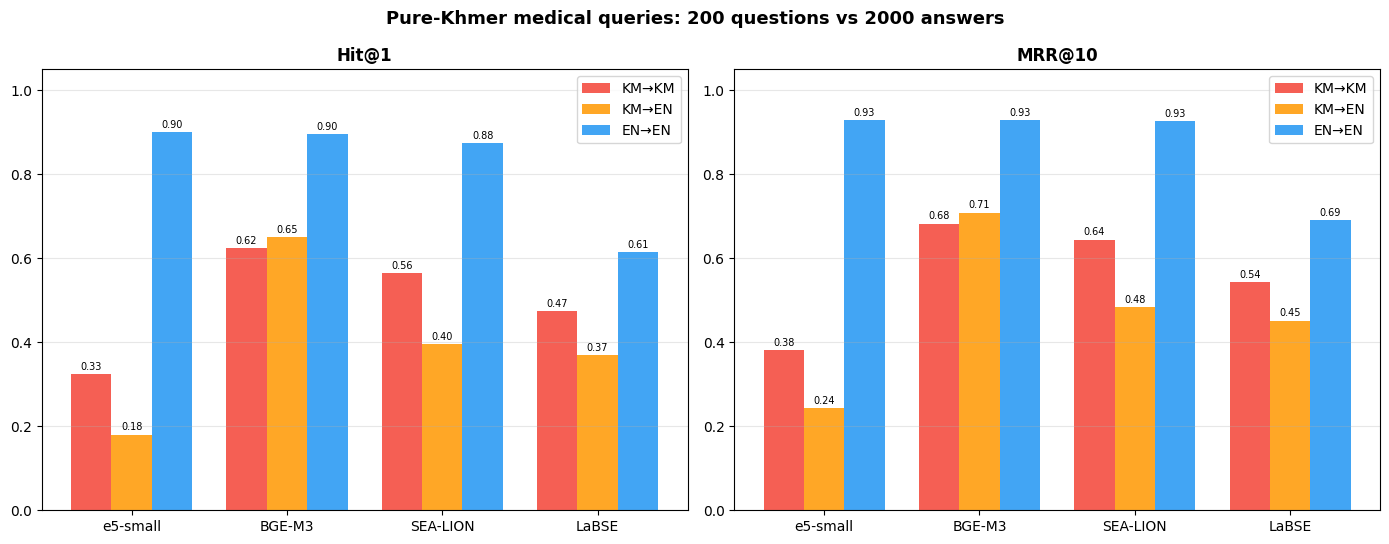

In [5]:
# Step 5: Plot
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle(f"Pure-Khmer medical queries: {N_QUERIES} questions vs {N_CORPUS} answers", fontsize=13, fontweight="bold")
colors = {"EN→EN": "#2196F3", "KM→KM": "#F44336", "KM→EN": "#FF9800"}
x, w = np.arange(len(MODELS)), 0.26
for ax, metric in zip(axes, ["Hit@1", "MRR@10"]):
    for i, (setting, _, _) in enumerate(SETTINGS):
        vals = [res[(res.model == m) & (res.setting == setting)][metric].item() for m in MODELS]
        bars = ax.bar(x + (i - 1) * w, vals, w, label=setting, color=colors[setting], alpha=0.85)
        for b in bars:
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.2f}", ha="center", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(list(MODELS))
    ax.set_ylim(0, 1.05); ax.set_title(metric, fontweight="bold"); ax.grid(axis="y", alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig("out/xling_part3.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

In [6]:
# Step 6: Failure examples for the best KM→EN model (what does it retrieve instead?)
best = res[res.setting == "KM→EN"].sort_values("MRR@10", ascending=False).iloc[0]["model"]
cfg = MODELS[best]
ranks = all_ranks[(best, "KM→EN")]
print(f"Best KM→EN model: {best}.  Rank distribution of the gold answer:")
print(pd.Series(ranks).describe()[["50%", "75%", "max"]].to_string())

m = cfg["model"]
bad = np.argsort(-ranks)[:3]
d_en = m.encode([cfg["dp"] + t for t in corpus["en"]], batch_size=64, normalize_embeddings=True)
for i in bad:
    q = m.encode([cfg["qp"] + queries["km"][i]], normalize_embeddings=True)
    top = int(np.argmax(q @ d_en.T))
    print(f"\n--- gold rank {ranks[i]}")
    print("Q (EN original):", queries["en"][i][:200])
    print("Gold answer    :", corpus["en"][i][:150])
    print("Retrieved #1   :", corpus["en"][top][:150])

Best KM→EN model: BGE-M3.  Rank distribution of the gold answer:
50%       1.00
75%       3.25
max    1900.00



--- gold rank 1900
Q (EN original): A 13-year-old young girl presents in the casualty with actue pain in the lower abdomen. She has history of cyclical pain for last 6 months and she has not attained her menarche yet. On local genital e
Gold answer    : C. Imperforate hymen
Retrieved #1   : Based on the clinical findings presented, the most likely diagnosis for the young female is Androgen Insensitivity Syndrome (AIS). This condition is c

--- gold rank 423
Q (EN original): A 79-year-old man develops dysuria, flank pain, and fever six days after hip replacement surgery. Despite antibiotic treatment, his symptoms persist. Further evaluation reveals the causal organism pro
Gold answer    : The class of antibiotic that was most likely used to treat his infection, which got inactivated through phosphorylation by the bacterial enzyme, is th
Retrieved #1   : The most likely diagnosis for the 65-year-old man experiencing these symptoms is ankylosing spondylitis. This condition is characteriz